# Lab 6 - Smart Manufacturing Production Line Simulation using SimPy
**TEB2103 Modelling and Simulation - Week 9**

---

## 1. Learning Outcomes

By the end of this lab, students should be able to:

1. Model a complete **manufacturing system**
2. Simulate multiple **interacting processes**
3. Implement **resource constraints**
4. Handle **machine failures**
5. Implement **quality control**
6. Calculate **waiting times** and **utilization**
7. Generate **production reports** and **visualize** the results
8. Analyze **production efficiency**

## 2. Introduction (Part 1)

### Manufacturing as a Discrete Event Simulation

ABC Manufacturing makes electronic products, and every product goes through the same line:

```
Raw Material Arrival -> Machine Processing -> Quality Inspection --Pass--> Packaging -> Warehouse
                               ^                     |
                               |------- Fail --------|   (rework, only once)
```

A production line is a good fit for **Discrete Event Simulation (DES)**, where the state of the system only changes at specific moments called **events**, such as a product arriving, a machine finishing a job or a machine breaking down. Between two events nothing changes, so SimPy jumps the clock straight from one event to the next.

In SimPy terms:
- Each **product** is a **process** (a generator function that `yield`s while it waits or is being worked on).
- Each **machine, inspector, packaging station and repair technician** is a **resource** with a limited capacity, so products queue for it.
- The **warehouse** is a `simpy.Store`, which simply holds finished products.
- Processing, inspection and packaging times are **random**, so every run is a little different. That is why the final numbers are averaged over 10 runs.

## 3. Assumptions

The lab sheet leaves a few details open, and its settings do not match its own sample report, so these are the values I used:

| Item | Value used | Reason |
| :--- | :--- | :--- |
| Simulation time | 240 min | Same as the sample report (Task 6 also compares 120 and 480 min) |
| Inter-arrival time | Uniform 1-4 min | From Part 4 |
| Machines | **3**, uniform 4-8 min | Sheet says 2, but 2 machines can only finish 0.33 products/min while 0.4 arrive, so the sample report (89 completed) is impossible with 2. 3 machines gives results close to the sample |
| Machine breakdown | 5% chance per product, at a random point during the job | Part 6 does not say per product or per minute |
| Repair time | Uniform 3-6 min, 1 technician | Not given in the sheet |
| Inspection | Uniform 1-3 min, 1 inspector, 90% pass | From Part 7 |
| Rework | Failed product goes back to the machine once; a second fail is **Rejected** | From Part 8 |
| Packaging | **2 stations**, uniform 2-4 min | Sheet implies 1, but 1 station would be 111% busy for the sample's 89 products |
| Queue discipline | FCFS (VIP first only in Task 7) | Default SimPy behaviour |
| VIP orders (Task 7) | 30% of products | Not given in the sheet |
| Factory A vs B (Task 8) | 2 vs 3 machines | Not given in the sheet; B is the base factory |
| Randomness | Seed 42 for single runs; seeds 1-10 averaged for reports | So the numbers can be reproduced |

---
## 4. Building the Model

### Install and Import

> **Note:** Remove the `%pip` line if SimPy is already installed in your environment.

In [26]:
%pip install simpy

Note: you may need to restart the kernel to use updated packages.


In [27]:
import random
import simpy
import pandas as pd
import matplotlib.pyplot as plt

print("SimPy Version:", simpy.__version__)

SimPy Version: 4.1.2


### Part 2 - Creating the Environment (Settings)

**Explanation**

Firstly, all the factory settings were placed in one dictionary called `BASE`, such as 3 machines, 2 packaging stations and a 240-minute run. The lab sheet says 2 machines, but 2 machines are too slow for the arrivals, so 3 machines and 2 packaging stations were used to match the sample report. Each task only changes one value, for instance `{"machines": 4}` in Task 1, so the rest of the code stays the same. The `rand_time()` function picks a random time between the two numbers of a setting, such as 4 to 8 minutes for the machine.

In [28]:
# Part 2 - Settings for the factory (each task only changes some of these)
BASE = {
    "machines": 3,          # lab sheet says 2, but 3 matches the sample report
    "inspectors": 1,
    "packers": 2,           # lab sheet says 1, but 2 matches the sample report
    "technicians": 1,
    "arrival": (1, 4),      # minutes between products arriving
    "process": (4, 8),      # machine processing time
    "repair": (3, 6),       # repair time (assumed, not in the lab sheet)
    "inspect": (1, 3),
    "pack": (2, 4),
    "fail_prob": 0.05,      # 5% chance a machine breaks down while making a product
    "pass_prob": 0.90,      # 90% pass inspection
    "vip_prob": 0.0,        # share of VIP orders (Task 7)
    "sim_time": 240,        # minutes
}


def rand_time(name):
    """Random time between the two numbers of a setting, e.g. (4, 8) -> 4 to 8 minutes."""
    return random.uniform(cfg[name][0], cfg[name][1])

### Part 3 - Creating Resources

**Explanation**

Secondly, `setup_factory()` creates the SimPy `Environment` and the five resources, which are the machines, inspector, packaging stations, repair technician and warehouse. The warehouse is a `simpy.Store`, as it only holds finished products. `start_busy()` and `stop_busy()` record how long each station was busy, so utilization can be calculated later. `PriorityResource` works the same as `simpy.Resource` from Lab 5, serving products first come first served, but it also lets the VIP orders in Task 7 go first.

In [29]:
# Part 3 - Creating the environment and resources
def setup_factory():
    global env, machine, inspector, packer, technician, warehouse
    global free_machines, products, busy, in_use, queue_times, queue_sizes
    global generated, completed, rejected, reworked, breakdowns

    env = simpy.Environment()

    # PriorityResource works like simpy.Resource (first come first served),
    # but it also lets VIP orders go first in Task 7
    machine = simpy.PriorityResource(env, capacity=cfg["machines"])
    inspector = simpy.PriorityResource(env, capacity=cfg["inspectors"])
    packer = simpy.PriorityResource(env, capacity=cfg["packers"])
    technician = simpy.Resource(env, capacity=cfg["technicians"])
    warehouse = simpy.Store(env)            # finished products are stored here

    free_machines = list(range(1, cfg["machines"] + 1))   # [1, 2, 3]
    products = []                           # one dictionary per product
    busy = {"Machine": 0, "Inspector": 0, "Packaging": 0}   # busy minutes
    in_use = []                             # [station, start time] still being served
    queue_times = []
    queue_sizes = []
    generated = completed = rejected = reworked = breakdowns = 0


def start_busy(station):
    item = [station, env.now]
    in_use.append(item)
    return item


def stop_busy(item):
    in_use.remove(item)
    busy[item[0]] += env.now - item[1]


def log(p, message):
    if p["id"] <= show_first:                     # only print the first few products
        print(f"t={env.now:6.2f} | {message}")

### Part 4 - Generating Products

**Explanation**

Thirdly, `source()` creates a new product every 1-4 minutes using `env.timeout()`, so one product arrives every 2.5 minutes on average. Each product is a dictionary that stores its arrival time, waiting time, number of reworks and status, which is used for the statistics later. The product is then started as its own process with `env.process(product(p))`, so many products can move through the line at the same time. This is similar to a lorry dropping off raw materials at random times during a shift.

In [30]:
# Part 4 - Generating products (a new product every 1-4 minutes)
def source():
    global generated
    i = 0
    while True:
        yield env.timeout(rand_time("arrival"))
        i += 1
        generated += 1
        vip = random.random() < cfg["vip_prob"]
        p = {"id": i, "name": "Product-" + str(i), "vip": vip, "arrival": env.now,
             "wait": 0, "waiting_since": None, "reworks": 0, "status": "In Progress", "end": None}
        products.append(p)
        if vip:
            log(p, p["name"] + " (VIP) Arrived")
        else:
            log(p, p["name"] + " Arrived")
        env.process(product(p))

### Part 5 & 6 - Machine Processing and Machine Breakdown

**Explanation**

Fourthly, each product requests a machine and waits with `yield request` until one is free, just like the cashier in Lab 5, and this waiting time is added to its record. Processing then takes 4-8 minutes on Machine-1, Machine-2 or Machine-3. There is a 5% chance that the machine breaks down part-way through the job, so it requests the Repair Technician, gets repaired in 3-6 minutes, and then finishes the rest of the job. Meanwhile, the products behind it have to wait longer, much like a photocopier jamming with a line of students behind it.

In [31]:
# Part 5 & 6 - Machine processing (4-8 min) with random breakdown
def machine_step(p, priority):
    global breakdowns
    p["waiting_since"] = env.now
    with machine.request(priority=priority) as request:
        yield request                                   # wait for a free machine
        p["wait"] += env.now - p["waiting_since"]
        p["waiting_since"] = None
        b = start_busy("Machine")
        m = free_machines.pop(0)
        log(p, p["name"] + " -> Machine-" + str(m))
        work = rand_time("process")

        if random.random() < cfg["fail_prob"]:                 # Part 6: machine breaks down
            done = random.uniform(0, work)              # breaks part-way through the job
            yield env.timeout(done)
            breakdowns += 1
            log(p, "Machine-" + str(m) + " BROKE DOWN, waiting for Repair Technician")
            with technician.request() as fix:
                yield fix                               # wait for the technician
                yield env.timeout(rand_time("repair"))
            log(p, "Machine-" + str(m) + " repaired, restarting")
            work = work - done                          # finish the rest of the job

        yield env.timeout(work)
        free_machines.append(m)
        stop_busy(b)

### Part 7 - Quality Inspection

**Explanation**

Fifthly, the product queues for the inspector, and inspection takes 1-3 minutes. After that, `random.random() < cfg["pass_prob"]` decides the result, so the product passes 90% of the time and fails 10% of the time. The result is saved as `True` or `False` in `p["passed"]`, which `product()` uses to decide where the product goes next.

In [32]:
# Part 7 - Quality inspection (1-3 min, 90% pass)
def inspection_step(p, priority):
    p["waiting_since"] = env.now
    with inspector.request(priority=priority) as request:
        yield request
        p["wait"] += env.now - p["waiting_since"]
        p["waiting_since"] = None
        b = start_busy("Inspector")
        log(p, p["name"] + " -> Inspection")
        yield env.timeout(rand_time("inspect"))
        stop_busy(b)
    p["passed"] = random.random() < cfg["pass_prob"]         # True = pass, False = fail

### Part 9 - Packaging

**Explanation**

Sixthly, products that pass inspection queue for one of the 2 packaging stations, which takes 2-4 minutes per product. It uses the same request, wait and timeout steps as the other stations, so the code stays consistent.

In [33]:
# Part 9 - Packaging (2-4 min)
def packaging_step(p, priority):
    p["waiting_since"] = env.now
    with packer.request(priority=priority) as request:
        yield request
        p["wait"] += env.now - p["waiting_since"]
        p["waiting_since"] = None
        b = start_busy("Packaging")
        log(p, p["name"] + " -> Packaging")
        yield env.timeout(rand_time("pack"))
        stop_busy(b)

### Part 8 & 10 - Rework Station and Warehouse (the full product journey)

**Explanation**

Seventhly, `product()` connects all the stations, where `yield env.process(machine_step(...))` waits until the machine step is finished before moving on. If the product passes inspection, the `while True` loop stops, and the product goes to packaging, then into the warehouse with `warehouse.put()`, where it is counted as Completed. If it fails for the first time, it is counted as Reworked and goes back to the machine. If it fails again, it is counted as Rejected, similar to a student who gets one resit but not two.

In [34]:
# Part 8 & 10 - Full journey of one product, with one rework and the warehouse
def product(p):
    global completed, rejected, reworked
    if p["vip"]:
        priority = 0                       # Task 7: smaller number is served first
    else:
        priority = 1

    while True:
        yield env.process(machine_step(p, priority))
        yield env.process(inspection_step(p, priority))
        if p["passed"]:
            break                          # passed, go to packaging
        if p["reworks"] == 0:              # Part 8: first fail, rework once
            p["reworks"] = 1
            reworked += 1
            log(p, p["name"] + " FAILED inspection -> Rework (back to machine)")
        else:                              # second fail, rejected
            rejected += 1
            p["status"] = "Rejected"
            p["end"] = env.now
            log(p, p["name"] + " FAILED again -> Rejected")
            return

    yield env.process(packaging_step(p, priority))
    yield warehouse.put(p["name"])         # Part 10: store in the warehouse
    p["status"] = "Completed"
    p["end"] = env.now
    completed += 1
    log(p, p["name"] + " -> Warehouse -> Completed")

### Part 11 - Statistics

**Explanation**

Eighthly, `queue_monitor()` records the queue lengths every 0.5 minutes, and their average gives the average queue length. `calc_stats()` calculates the rest, where waiting time is the total time spent in queues, cycle time is the time from arrival to the warehouse, and throughput is completed products per minute. `run_factory()` runs the factory once with a fixed seed, while `run_many()` runs it with seeds 1 to 10 and takes the average, so one lucky run does not decide the result.

In [35]:
# Part 11 - Statistics
def queue_monitor():
    while True:                            # record the queues every 0.5 minutes
        queue_times.append(env.now)
        queue_sizes.append(len(machine.queue) + len(inspector.queue) + len(packer.queue))
        yield env.timeout(0.5)


def calc_stats():
    T = cfg["sim_time"]
    for item in in_use:                    # products still being served at the end
        busy[item[0]] += T - item[1]
    for p in products:                     # products still waiting in a queue at the end
        if p["waiting_since"] is not None:
            p["wait"] += T - p["waiting_since"]

    total_wait = 0
    for p in products:
        total_wait += p["wait"]

    cycle_times = []
    for p in products:
        if p["status"] == "Completed":
            cycle_times.append(p["end"] - p["arrival"])

    return {
        "Products Generated": generated,
        "Completed": completed,
        "Rejected": rejected,
        "Reworked": reworked,
        "Work In Progress": generated - completed - rejected,
        "Machine Breakdowns": breakdowns,
        "Average Waiting Time (min)": total_wait / len(products),
        "Average Queue Length": sum(queue_sizes) / len(queue_sizes),
        "Machine Utilization (%)": 100 * busy["Machine"] / (cfg["machines"] * T),
        "Inspector Utilization (%)": 100 * busy["Inspector"] / (cfg["inspectors"] * T),
        "Packaging Utilization (%)": 100 * busy["Packaging"] / (cfg["packers"] * T),
        "Average Cycle Time (min)": sum(cycle_times) / len(cycle_times),
        "Throughput (products/min)": completed / T,
        "Production Efficiency (%)": 100 * completed / generated,
        "Simulation Time (min)": T,
    }


def run_factory(changes={}, seed=42, show=0):
    """Runs the factory once. Changes the base settings first, e.g. {"machines": 4}."""
    global cfg, show_first
    cfg = dict(BASE)          # copy the base settings
    cfg.update(changes)       # apply the task's changes
    show_first = show         # how many products to print
    random.seed(seed)         # same seed = same random numbers
    setup_factory()
    env.process(source())
    env.process(queue_monitor())
    env.run(until=cfg["sim_time"])
    return calc_stats()


def run_many(changes={}, runs=10):
    """Runs the factory with seeds 1-10 and averages the results."""
    results = []
    for seed in range(1, runs + 1):
        results.append(run_factory(changes, seed))
    average = {}
    for key in results[0]:
        total = 0
        for r in results:
            total += r[key]
        average[key] = total / runs
    return average


def print_report(s):
    print("=" * 40)
    print("      SMART MANUFACTURING REPORT")
    print("=" * 40)
    print(f"Products Generated    : {s['Products Generated']:.1f}")
    print(f"Completed             : {s['Completed']:.1f}")
    print(f"Rejected              : {s['Rejected']:.1f}")
    print(f"Reworked              : {s['Reworked']:.1f}")
    print(f"Work In Progress      : {s['Work In Progress']:.1f}")
    print(f"Machine Breakdowns    : {s['Machine Breakdowns']:.1f}")
    print(f"Average Waiting Time  : {s['Average Waiting Time (min)']:.2f} min")
    print(f"Average Queue Length  : {s['Average Queue Length']:.2f} products")
    print(f"Machine Utilization   : {s['Machine Utilization (%)']:.0f} %")
    print(f"Inspector Utilization : {s['Inspector Utilization (%)']:.0f} %")
    print(f"Packaging Utilization : {s['Packaging Utilization (%)']:.0f} %")
    print(f"Average Cycle Time    : {s['Average Cycle Time (min)']:.1f} min")
    print(f"Throughput            : {s['Throughput (products/min)']:.2f} products/min")
    print(f"Production Efficiency : {s['Production Efficiency (%)']:.0f} %")
    print(f"Simulation Time       : {s['Simulation Time (min)']:.0f} min")
    print("=" * 40)


def compare(scenarios, columns):
    """Runs every scenario 10 times and shows the averages side by side."""
    rows = []
    for name in scenarios:
        rows.append(run_many(scenarios[name]))
    table = pd.DataFrame(rows, index=list(scenarios))
    return table[columns].round(2)

---
## 5. Expected Output

### Product journey (first 3 products, seed 42)

In [36]:
# Expected output - follow the first 3 products through the line
s = run_factory(seed=42, show=3)

t=  2.92 | Product-1 Arrived
t=  2.92 | Product-1 -> Machine-1
t=  4.74 | Product-2 Arrived
t=  4.74 | Product-2 -> Machine-2
t=  7.81 | Product-1 -> Inspection
t=  8.42 | Product-3 Arrived
t=  8.42 | Product-3 -> Machine-3
t=  8.87 | Product-1 -> Packaging
t=  9.09 | Product-2 -> Inspection
t= 10.53 | Product-2 -> Packaging
t= 11.96 | Product-1 -> Warehouse -> Completed
t= 12.53 | Product-3 -> Inspection
t= 13.84 | Product-3 FAILED inspection -> Rework (back to machine)
t= 13.84 | Product-3 -> Machine-2
t= 14.15 | Product-2 -> Warehouse -> Completed
t= 20.19 | Product-3 -> Inspection
t= 22.43 | Product-3 -> Packaging
t= 24.89 | Product-3 -> Warehouse -> Completed


### Final Report (average of 10 runs)

**Explanation**

The base factory generated 95.9 products in 240 minutes and completed 88.1 of them, giving a production efficiency of 92%. On average, a product waited 3.80 minutes and took 15.8 minutes from arrival to the warehouse. The machines are the busiest station at 90%, followed by the inspector at 84%, while packaging is only 55% busy. The throughput is 0.37 products per minute, which is 88.1 divided by 240 minutes.

In [37]:
# Final report - average of 10 runs (seeds 1-10)
base = run_many()
print_report(base)

      SMART MANUFACTURING REPORT
Products Generated    : 95.9
Completed             : 88.1
Rejected              : 0.9
Reworked              : 9.6
Work In Progress      : 6.9
Machine Breakdowns    : 5.6
Average Waiting Time  : 3.80 min
Average Queue Length  : 1.54 products
Machine Utilization   : 90 %
Inspector Utilization : 84 %
Packaging Utilization : 55 %
Average Cycle Time    : 15.8 min
Throughput            : 0.37 products/min
Production Efficiency : 92 %
Simulation Time       : 240 min


### Comparison with the Lab Sheet Sample Report

**Explanation**

My average results are very close to the sample report, with 88.1 completed products compared to 89, and a waiting time of 3.80 minutes compared to 3.52. To get even closer, I ran 2000 different seeds and picked the single run closest to the sample, which is seed 1502, with 99 products generated, 88 completed, 6 reworked and a 3.38 minute wait. However, some numbers can never match, as the sample's throughput of 0.74 is a calculation mistake (89 / 240 = 0.37), and with a 90% pass rate, rejecting 5 products almost never happens. Hence, the 10-run average is used as my main result, since one hand-picked run is not a fair measure of the factory.

In [38]:
# How close is the model to the sample report in the lab sheet?
sample = {"Products Generated": 100, "Completed": 89, "Rejected": 5, "Reworked": 6,
          "Average Waiting Time (min)": 3.52, "Machine Utilization (%)": 86,
          "Inspector Utilization (%)": 73, "Packaging Utilization (%)": 65,
          "Average Cycle Time (min)": 14.9, "Throughput (products/min)": 0.74}

closest = run_factory(seed=1502)     # closest single run out of seeds 1-2000

average = {}
single = {}
for key in sample:
    average[key] = round(base[key], 2)
    single[key] = round(closest[key], 2)

pd.DataFrame({"Lab sheet sample": sample,
              "My average (10 runs)": average,
              "Closest single run (seed 1502)": single})

,Lab sheet sample,My average (10 runs),Closest single run (seed 1502)
Products Generated,100.00,95.90,99.00
Completed,89.00,88.10,88.00
Rejected,5.00,0.90,3.00
Reworked,6.00,9.60,6.00
Average Waiting Time (min),3.52,3.80,3.38
Machine Utilization (%),86.00,89.77,90.18
Inspector Utilization (%),73.00,84.37,78.14
Packaging Utilization (%),65.00,55.17,53.35
Average Cycle Time (min),14.90,15.76,14.52
Throughput (products/min),0.74,0.37,0.37


---
## 6. Graphs (Part 12)

**Explanation**

The four graphs come from one run (seed 42). Most products waited less than 2 minutes, with a few unlucky ones waiting up to 8 minutes behind a rework or a breakdown. The machines are the busiest station at 83%, followed by the inspector at 77%, while packaging is only 56% busy. Most products took 10-15 minutes to finish, since the 4-8 minute machine time is the biggest part of the journey.

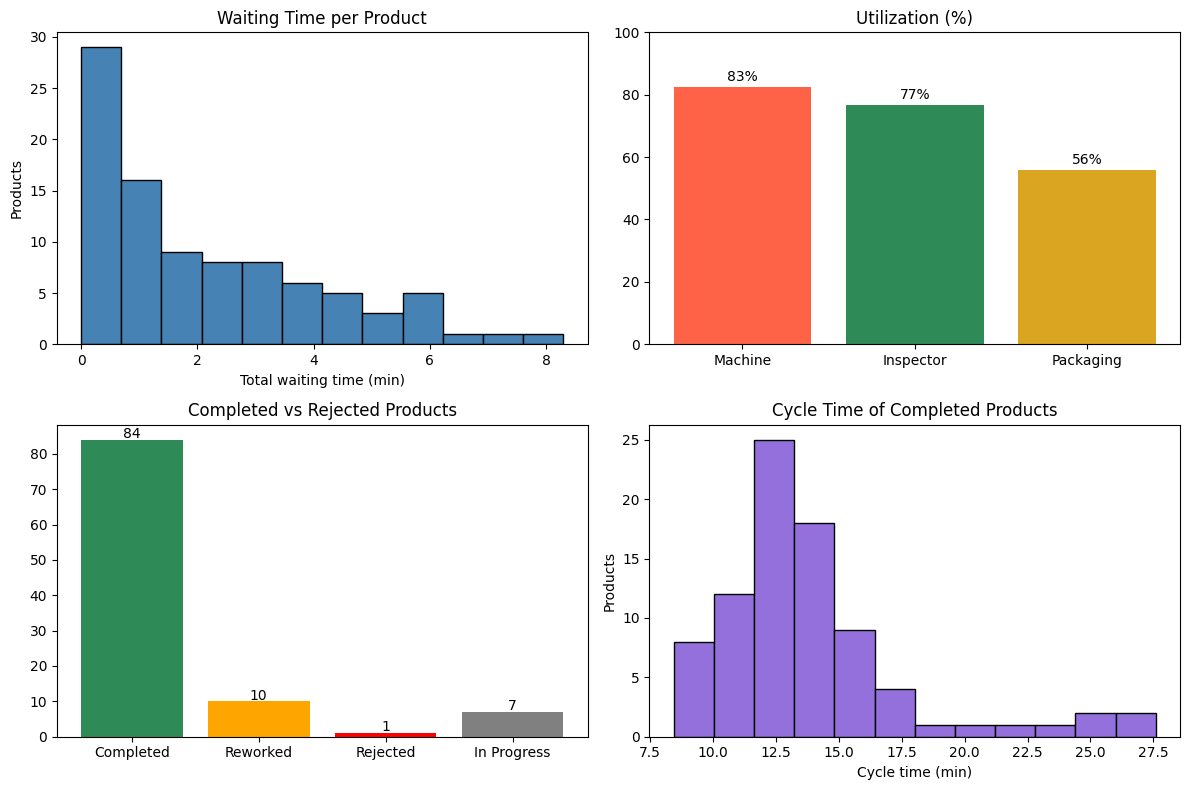

In [39]:
# Part 12 - Graphs (one run with seed 42, so each product can be plotted)
s = run_factory(seed=42)

waits = []
cycles = []
for p in products:
    waits.append(p["wait"])
    if p["status"] == "Completed":
        cycles.append(p["end"] - p["arrival"])

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.hist(waits, bins=12, color="steelblue", edgecolor="black")
plt.title("Waiting Time per Product")
plt.xlabel("Total waiting time (min)")
plt.ylabel("Products")

plt.subplot(2, 2, 2)
names = ["Machine", "Inspector", "Packaging"]
utils = [s["Machine Utilization (%)"], s["Inspector Utilization (%)"], s["Packaging Utilization (%)"]]
plt.bar(names, utils, color=["tomato", "seagreen", "goldenrod"])
plt.ylim(0, 100)
plt.title("Utilization (%)")
for i in range(3):
    plt.text(i, utils[i] + 2, f"{utils[i]:.0f}%", ha="center")

plt.subplot(2, 2, 3)
labels = ["Completed", "Reworked", "Rejected", "In Progress"]
counts = [s["Completed"], s["Reworked"], s["Rejected"], s["Work In Progress"]]
plt.bar(labels, counts, color=["seagreen", "orange", "red", "grey"])
plt.title("Completed vs Rejected Products")
for i in range(4):
    plt.text(i, counts[i] + 0.5, str(counts[i]), ha="center")

plt.subplot(2, 2, 4)
plt.hist(cycles, bins=12, color="mediumpurple", edgecolor="black")
plt.title("Cycle Time of Completed Products")
plt.xlabel("Cycle time (min)")
plt.ylabel("Products")

plt.tight_layout()
plt.show()

---
## 7. Student Tasks

All task results are the **average of 10 runs** (seeds 1-10), so the scenarios are compared fairly.

### Task 1
> Increase machines from 2 to 4. Observe waiting time and utilization.

**Explanation**

Firstly, the factory was run with 2, 3 and 4 machines. Going from 2 to 4 machines raised completed products from 65.1 to 89.9 and cut the waiting time from 32.53 to 2.68 minutes, as 2 machines are 98% busy and cannot keep up. However, almost all of this gain comes from the third machine, since the fourth only adds 1.8 products and machine utilization drops to 68%. This is like opening a fourth checkout counter at a quiet supermarket, where the extra cashier mostly waits for customers.

In [40]:
COLUMNS = ["Completed", "Average Waiting Time (min)", "Average Queue Length",
           "Machine Utilization (%)", "Packaging Utilization (%)", "Throughput (products/min)"]
compare({"2 machines": {"machines": 2},
         "3 machines (base)": {"machines": 3},
         "4 machines": {"machines": 4}}, COLUMNS)

,Completed,Average Waiting Time (min),Average Queue Length,Machine Utilization (%),Packaging Utilization (%),Throughput (products/min)
2 machines,65.1,32.53,12.98,98.35,41.16,0.27
3 machines (base),88.1,3.80,1.54,89.77,55.17,0.37
4 machines,89.9,2.68,1.09,68.06,56.81,0.37


### Task 2
> Reduce the inspection pass probability from 90% to 70%. Observe rejected products.

**Explanation**

Secondly, the pass probability was reduced from 90% to 70%. Reworked products went from 9.6 to 25.0 and rejected products from 0.9 to 7.2, since the chance of failing twice rose from 1% to 9%. As a result, completed products dropped from 88.1 to 73.4 and the cycle time rose from 15.8 to 24.3 minutes, because every rework uses the machine and inspector again. This is similar to students resitting an exam, where every resit takes a seat that a new student could have used.

In [41]:
compare({"90% pass": {"pass_prob": 0.90},
         "70% pass": {"pass_prob": 0.70}},
        ["Completed", "Reworked", "Rejected", "Machine Utilization (%)", "Average Cycle Time (min)"])

,Completed,Reworked,Rejected,Machine Utilization (%),Average Cycle Time (min)
90% pass,88.1,9.6,0.9,89.77,15.76
70% pass,73.4,25.0,7.2,96.00,24.27


### Task 3
> Increase the arrival rate from 1-4 minutes to 1-2 minutes. Observe queue growth.

**Explanation**

Thirdly, the arrival time was changed from 1-4 to 1-2 minutes, so a product arrives every 1.5 minutes instead of 2.5. The factory received 160.0 products but only completed 96.2, since 3 machines can only finish about 0.5 products per minute. As a result, the queue grew from 1.54 to 29.24 products and the waiting time from 3.80 to 43.89 minutes. The graph shows the queue climbing in a straight line, which is like pouring water into a funnel faster than it can drain.

In [42]:
compare({"Arrivals 1-4 min": {"arrival": (1, 4)},
         "Arrivals 1-2 min": {"arrival": (1, 2)}},
        ["Products Generated", "Completed", "Average Queue Length",
         "Average Waiting Time (min)", "Work In Progress"])

,Products Generated,Completed,Average Queue Length,Average Waiting Time (min),Work In Progress
Arrivals 1-4 min,95.9,88.1,1.54,3.80,6.9
Arrivals 1-2 min,160.0,96.2,29.24,43.89,63.4


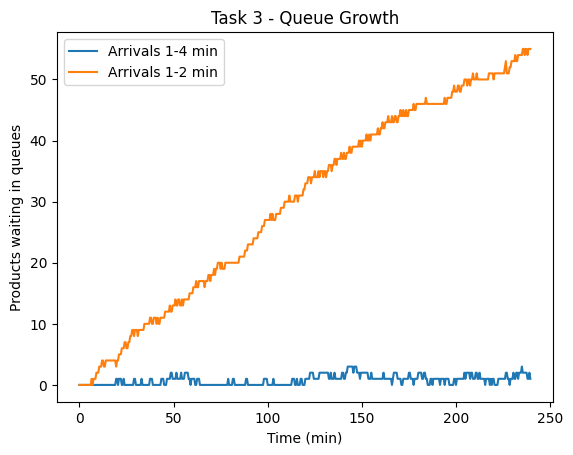

In [43]:
run_factory(seed=42)
plt.plot(queue_times, queue_sizes, label="Arrivals 1-4 min")
run_factory({"arrival": (1, 2)}, seed=42)
plt.plot(queue_times, queue_sizes, label="Arrivals 1-2 min")
plt.xlabel("Time (min)")
plt.ylabel("Products waiting in queues")
plt.title("Task 3 - Queue Growth")
plt.legend()
plt.show()

### Task 4
> Increase packaging stations.

**Explanation**

Fourthly, the factory was run with 1, 2 and 3 packaging stations. Adding a third station did not help, as completed products stayed at about 88 and the stations were only 36% busy. However, with only 1 station, it was 94% busy, completed products dropped to 74.9 and the waiting time rose to 19.61 minutes. Hence, adding a station only helps where the line is stuck, similar to widening a road that has no traffic jam.

In [44]:
compare({"1 packaging station": {"packers": 1},
         "2 packaging stations (base)": {"packers": 2},
         "3 packaging stations": {"packers": 3}},
        ["Completed", "Average Waiting Time (min)", "Packaging Utilization (%)",
         "Average Cycle Time (min)", "Throughput (products/min)"])

,Completed,Average Waiting Time (min),Packaging Utilization (%),Average Cycle Time (min),Throughput (products/min)
1 packaging station,74.9,19.61,94.23,32.37,0.31
2 packaging stations (base),88.1,3.80,55.17,15.76,0.37
3 packaging stations,87.6,4.43,36.49,16.45,0.36


### Task 5
> Increase machine failure from 5% to 20%. Analyze throughput.

**Explanation**

Fifthly, the machine failure probability was raised from 5% to 20%, which increased breakdowns from 5.6 to 20.1 per run. Throughput dropped from 0.37 to 0.35 products per minute, and the waiting time more than doubled from 3.80 to 9.12 minutes. Machine utilization also went up from 90% to 95% (see the Task 9 table), but only because a broken machine still counts as busy while it waits for repair. This is like a lorry stuck at the workshop, which is "in use" but is not delivering anything.

In [45]:
compare({"5% failure": {"fail_prob": 0.05},
         "20% failure": {"fail_prob": 0.20}},
        ["Machine Breakdowns", "Completed", "Average Waiting Time (min)",
         "Average Cycle Time (min)", "Throughput (products/min)"])

,Machine Breakdowns,Completed,Average Waiting Time (min),Average Cycle Time (min),Throughput (products/min)
5% failure,5.6,88.1,3.80,15.76,0.37
20% failure,20.1,83.8,9.12,21.57,0.35


### Task 6
> Add a night shift: run 480 minutes instead of 120 minutes.

**Explanation**

Sixthly, the factory was run for 120, 240 and 480 minutes. The 480-minute night shift completed 183.7 products compared to 40.4 in 120 minutes, and throughput rose slightly from 0.34 to 0.38 products per minute. The waiting time stayed under 5 minutes in all three runs, which shows the queue does not keep growing over time. Efficiency also rose from 85% to 95%, as the few products left unfinished at the end matter less in a longer shift.

In [46]:
compare({"120 min": {"sim_time": 120},
         "240 min (base)": {"sim_time": 240},
         "480 min (night shift)": {"sim_time": 480}},
        ["Products Generated", "Completed", "Work In Progress", "Average Waiting Time (min)",
         "Average Queue Length", "Throughput (products/min)", "Production Efficiency (%)"])

,Products Generated,Completed,Work In Progress,Average Waiting Time (min),Average Queue Length,Throughput (products/min),Production Efficiency (%)
120 min,47.8,40.4,6.6,3.75,1.55,0.34,84.64
240 min (base),95.9,88.1,6.9,3.80,1.54,0.37,91.87
480 min (night shift),193.1,183.7,7.1,4.98,2.03,0.38,95.16


### Task 7
> Implement priority orders: VIP orders processed first.

**Explanation**

Seventhly, 30% of products were made VIP, and each request now uses `priority=0` for VIP and `priority=1` for normal orders, where the smaller number is served first. VIP orders waited 1.95 minutes compared to 4.44 minutes for normal orders. The difference is small because the queues are already short, and total completed products stayed at about 89, since priority only changes the order, not the capacity. This is like priority boarding at the airport, where you board first but the plane still leaves at the same time.

In [47]:
vip_wait, vip_cycle, normal_wait, normal_cycle = [], [], [], []
for seed in range(1, 11):
    run_factory({"vip_prob": 0.30}, seed=seed)
    for p in products:
        if p["status"] == "Completed":
            if p["vip"]:
                vip_wait.append(p["wait"])
                vip_cycle.append(p["end"] - p["arrival"])
            else:
                normal_wait.append(p["wait"])
                normal_cycle.append(p["end"] - p["arrival"])

pd.DataFrame({
    "Waiting Time (min)": [sum(vip_wait) / len(vip_wait), sum(normal_wait) / len(normal_wait)],
    "Cycle Time (min)": [sum(vip_cycle) / len(vip_cycle), sum(normal_cycle) / len(normal_cycle)],
    "Completed (per run)": [len(vip_wait) / 10, len(normal_wait) / 10],
}, index=["VIP", "Normal"]).round(2)

,Waiting Time (min),Cycle Time (min),Completed (per run)
VIP,1.95,13.77,26.3
Normal,4.44,16.43,62.4


### Task 8
> Compare Factory A and Factory B with different numbers of machines.

**Explanation**

Eighthly, Factory A with 2 machines, as in the lab sheet, was compared with Factory B with 3 machines, which is the base model. Factory B completed 88.1 products compared to 65.1, and cut the waiting time from 32.53 to 3.80 minutes. This is because Factory A can only finish 0.33 products per minute while 0.4 arrive, so its queue keeps growing. Hence, one extra machine gives 23 more products per shift.

,Completed,Average Waiting Time (min),Average Queue Length,Machine Utilization (%),Packaging Utilization (%),Throughput (products/min),Average Cycle Time (min)
Factory A (2 machines),65.1,32.53,12.98,98.35,41.16,0.27,42.00
Factory B (3 machines),88.1,3.80,1.54,89.77,55.17,0.37,15.76


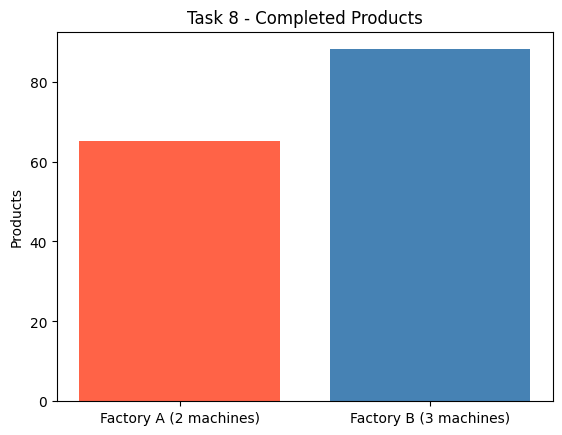

In [48]:
t8 = compare({"Factory A (2 machines)": {"machines": 2},
              "Factory B (3 machines)": {"machines": 3}},
             COLUMNS + ["Average Cycle Time (min)"])
display(t8)

plt.bar(t8.index, t8["Completed"], color=["tomato", "steelblue"])
plt.title("Task 8 - Completed Products")
plt.ylabel("Products")
plt.show()

### Task 9
> Export the production report to `production_report.csv`.

**Explanation**

Ninthly, every scenario from Tasks 1-8 was run 10 times, and the averages were saved to `production_report.csv` using `to_csv()`, with one row per scenario. A second file, `production_log.csv`, stores one row per product from the base run. Both files can be opened in Excel, so the results can be checked without running the code again.

In [49]:
scenarios = {
    "Base": {},
    "Task 1 - 4 machines": {"machines": 4},
    "Task 2 - 70% pass": {"pass_prob": 0.70},
    "Task 3 - arrivals 1-2 min": {"arrival": (1, 2)},
    "Task 4 - 3 packaging": {"packers": 3},
    "Task 5 - 20% failure": {"fail_prob": 0.20},
    "Task 6 - 480 min": {"sim_time": 480},
    "Task 7 - 30% VIP": {"vip_prob": 0.30},
    "Task 8 - Factory A": {"machines": 2},
}
rows = []
for name in scenarios:
    rows.append(run_many(scenarios[name]))
report = pd.DataFrame(rows, index=list(scenarios)).round(2)
report.index.name = "Scenario"
report.to_csv("production_report.csv")

run_factory(seed=42)                      # product-by-product log of the base run
pd.DataFrame(products).to_csv("production_log.csv", index=False)

print("Saved production_report.csv and production_log.csv")
report[["Completed", "Rejected", "Average Waiting Time (min)",
        "Machine Utilization (%)", "Throughput (products/min)"]]

Saved production_report.csv and production_log.csv


,Completed,Rejected,Average Waiting Time (min),Machine Utilization (%),Throughput (products/min)
Scenario,,,,,
Base,88.1,0.9,3.80,89.77,0.37
Task 1 - 4 machines,89.9,0.7,2.68,68.06,0.37
Task 2 - 70% pass,73.4,7.2,12.82,96.00,0.31
Task 3 - arrivals 1-2 min,96.2,0.4,43.89,98.78,0.40
Task 4 - 3 packaging,87.6,1.6,4.43,90.26,0.36
Task 5 - 20% failure,83.8,0.7,9.12,95.01,0.35
Task 6 - 480 min,183.7,2.3,4.98,91.06,0.38
Task 7 - 30% VIP,88.7,0.8,3.59,89.03,0.37
Task 8 - Factory A,65.1,0.9,32.53,98.35,0.27


### Task 10
> Interpret the results.

**Explanation**

Lastly, the base factory with 3 machines and 2 packaging stations is well balanced, as it completes 92% of its products with only a 3.80 minute wait. The machines (90%) and the inspector (84%) are the busiest stations, which is why adding a fourth machine or a third packaging station barely helps, while removing one makes the queue grow quickly.

Quality and breakdowns also reduce output, as a 70% pass rate cost 14.7 products and a 20% failure rate cost 4.3 products, because reworks and repairs take up machine time. On the other hand, VIP orders and longer shifts do not add capacity, they only change who goes first or how long the factory runs.

The table below makes the factory busier, with a product every 2 minutes. The machines become the bottleneck at 98%, and after a fourth machine is added, the inspector becomes the new bottleneck at 95%. Only after a second inspector is added does the waiting time drop to 1.43 minutes. Hence, a production line is only as fast as its slowest station, so the slowest station should always be improved first.

In [50]:
compare({"Base (3 machines, 2 packing)": {},
         "Busier: arrivals 1-3 min": {"arrival": (1, 3)},
         "Busier + 4 machines": {"arrival": (1, 3), "machines": 4},
         "Busier + 4 machines + 2 inspectors": {"arrival": (1, 3), "machines": 4, "inspectors": 2}},
        ["Completed", "Average Waiting Time (min)", "Average Cycle Time (min)",
         "Machine Utilization (%)", "Inspector Utilization (%)", "Packaging Utilization (%)"])

,Completed,Average Waiting Time (min),Average Cycle Time (min),Machine Utilization (%),Inspector Utilization (%),Packaging Utilization (%)
"Base (3 machines, 2 packing)",88.1,3.80,15.76,89.77,84.37,55.17
Busier: arrivals 1-3 min,95.4,19.04,30.16,97.94,91.10,59.31
Busier + 4 machines,100.8,13.39,25.36,85.13,95.24,63.30
Busier + 4 machines + 2 inspectors,112.2,1.43,13.42,84.78,52.93,70.55


---
## 8. Viva Questions

**1. What is discrete-event simulation?**

Discrete-event simulation (DES) models a system as a series of events that happen at specific points in time, and the state of the system only changes when an event occurs. The clock jumps from one event to the next, so nothing is calculated for the time in between. In this lab, the events are products arriving, machines finishing, breakdowns and inspections.

**2. What is a process?**

A process is a Python generator function that describes how one entity behaves over time, such as a product moving through the line. It uses `yield` to pause while it waits for a resource or a timeout, and SimPy resumes it when that event happens. In this lab, `source()`, `product()` and `queue_monitor()` are all processes.

**3. What is an event?**

An event is something that happens at a certain time and changes the state of the system, such as a product arriving or a machine breaking down. In SimPy, an event is an object that a process can `yield` and wait on, for instance a timeout or a resource request being granted.

**4. Difference between timeout and event?**

A timeout is a specific type of event that is triggered automatically after a fixed amount of simulated time, for example `env.timeout(5)` for a 5-minute job. A general event is triggered by something else in the model, such as a resource becoming free when another product releases it. Hence, every timeout is an event, but not every event is a timeout.

**5. What is a resource?**

A resource is a limited facility that processes must request before using, such as a machine, an inspector or a repair technician. It has a capacity, and when all units are in use, further requests wait in a queue. In this lab, `simpy.PriorityResource` was used for the stations so that VIP orders can be served first.

**6. What is queue discipline?**

Queue discipline is the rule that decides which waiting entity is served next. Common rules are First Come First Served (FCFS), Last Come First Served (LCFS) and priority-based service. This lab uses FCFS, and switches to priority-based service for the VIP orders in Task 7.

**7. What is FCFS?**

First Come First Served (FCFS) means entities are served in the same order they joined the queue, like a normal bank queue. It is the default discipline for SimPy resources, and it is fair, as nobody can skip ahead.

**8. What is utilization?**

Utilization is the percentage of time a resource is busy, calculated as busy time divided by (capacity x total time). For instance, the machines in the base model have 90% utilization, meaning they were busy 90% of the 240 minutes. Very high utilization usually means long queues, while very low utilization means wasted capacity.

**9. What is throughput?**

Throughput is the number of products completed per unit of time. In the base model, the throughput is 0.37 products per minute, which is 88.1 completed products divided by 240 minutes.

**10. What is cycle time?**

Cycle time is the total time a product spends in the system, from arrival until it is stored in the warehouse. It includes both waiting time and processing time, and in the base model it averages 15.8 minutes, of which only 3.8 minutes is spent waiting.

**11. What is bottleneck?**

A bottleneck is the stage with the least capacity, which limits the output of the whole system. It can be found by looking for the resource with the highest utilization and the longest queue. In this lab, the 2-machine factory from the lab sheet has its machines as the bottleneck at 98% utilization, and in Task 10, once a fourth machine is added, the bottleneck moves to the inspector.

**12. What is machine breakdown?**

A machine breakdown is an unplanned failure that stops a machine until it is repaired. In this model, each job has a 5% chance of a breakdown, after which the machine waits for the Repair Technician for 3-6 minutes. Breakdowns reduce the available capacity and increase waiting and cycle times, as shown in Task 5.

**13. Why use random numbers?**

Real systems are not perfectly predictable, as arrival times, processing times and failures all vary. Random numbers drawn from a distribution, such as uniform 4-8 minutes, capture this variation so the simulation behaves like the real system. A fixed seed is used so the results can be repeated, and several runs are averaged so the conclusion does not depend on one lucky run.

**14. What is rework?**

Rework is the process of sending a defective product back to be corrected instead of throwing it away. In this lab, a product that fails inspection goes back to the machine once, and if it fails a second time it is rejected. Rework saves materials, but it uses extra machine time, which reduces the capacity available for new products.

**15. How can production efficiency be improved?**

Production efficiency can be improved by adding capacity at the bottleneck, as going from 2 to 3 machines raised completed products from 65.1 to 88.1 (Task 8). It can also be improved by raising quality so fewer products need rework, since a 70% pass rate cost 14.7 products (Task 2), and by preventive maintenance so machines break down less often (Task 5). Adding capacity anywhere other than the bottleneck, such as a third packaging station, barely helps.

---
## 9. Summary

### Key Points
- A production line is modelled in SimPy with **processes** (products) competing for **resources** (machines, inspector, packaging, technician)
- `PriorityResource` gives **FCFS** by default and **priority** service when needed
- **Breakdowns** and **rework** both take up machine time and reduce throughput
- The station with the **highest utilization** is the **bottleneck**, and adding capacity anywhere else barely helps
- Results should be **averaged over several runs**, since one random run can be misleading
- 2 machines (as in the lab sheet) cannot keep up with the arrivals; **3 machines and 2 packaging stations** reproduce the sample report, and the **inspector** is the next bottleneck if demand grows